Load Data

In [ ]:
# code made by student: Aeddan G Anderson Student ID: U2380199 
!pip install scikit-learn pandas #installs pandas so that data frame manipulation can be done
import pandas as pd # imports the pandas librairy and shortens notation
import numpy as np # needed for data analysis
import seaborn as sns # needed for analysis
import matplotlib.pyplot as plt # needed for analysis
from scipy import stats # needed for analysis

df = pd.read_csv('hotel_bookings.csv')
df

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07


#Preprocessing Section

Deleted coloums

In [46]:
df.isnull().sum() # shows the number of total null values for varibles in data set done to get an understanding of what is missing and what needs to be done

,0
hotel,0
is_canceled,0
lead_time,0
arrival_date_year,0
arrival_date_month,0
arrival_date_week_number,0
arrival_date_day_of_month,0
stays_in_weekend_nights,0
stays_in_week_nights,0
adults,0


In [47]:
df = df.drop('company', axis=1)#drops the company data coloum as most of them are null, as shown by the code block above. this may impact accuracy but so many rows are NaN that the impact if any would be minimal
df = df.drop('arrival_date_year', axis=1) # drops the arrival_date_year coloum as it has no effect on future predictions
df = df.drop('reservation_status_date', axis=1) # drops reservation_status_date coloum as it has no effect on future predictions
df = df.drop('agent', axis=1) #drops the agent coloum as there are many NaN values, this may impact accuracy but so many rows are NaN that the impact if any would be minimal
df = df.drop('country', axis=1) # drops the country coloum as encoding the countries would be detramental to the AI as too many columns would be present in the data set
df = df.drop('arrival_date_day_of_month', axis=1) # drops the arrival_date_day_of_month coloum as it is a date and irreleivant
df = df.drop('assigned_room_type', axis=1) # drops the assigned_room_type as if it is assigned, then it has no corraltion to cancleation eg. for a room to be assigned a guest has to show up
df = df.drop('reservation_status', axis=1) # drops the reservation_status as the is_canceled coloum already provides the needed infomation
df = df.drop('distribution_channel', axis=1) # drops the distribtution_ channel as the enconding would be detramental to the AI learning as there would too many columns
df = df.drop('arrival_date_month', axis=1) # drops the arrival_date_month as the arrival_date_week does a simular thing, with weeks being able to turn into months
df = df.drop('market_segment', axis=1)

df

,hotel,is_canceled,lead_time,arrival_date_week_number,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,...,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,booking_changes,deposit_type,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests
0,Resort Hotel,0,342,27,0,0,2,0.0,0,BB,...,0,0,C,3,No Deposit,0,Transient,0.00,0,0
1,Resort Hotel,0,737,27,0,0,2,0.0,0,BB,...,0,0,C,4,No Deposit,0,Transient,0.00,0,0
2,Resort Hotel,0,7,27,0,1,1,0.0,0,BB,...,0,0,A,0,No Deposit,0,Transient,75.00,0,0
3,Resort Hotel,0,13,27,0,1,1,0.0,0,BB,...,0,0,A,0,No Deposit,0,Transient,75.00,0,0
4,Resort Hotel,0,14,27,0,2,2,0.0,0,BB,...,0,0,A,0,No Deposit,0,Transient,98.00,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,35,2,5,2,0.0,0,BB,...,0,0,A,0,No Deposit,0,Transient,96.14,0,0
119386,City Hotel,0,102,35,2,5,3,0.0,0,BB,...,0,0,E,0,No Deposit,0,Transient,225.43,0,2
119387,City Hotel,0,34,35,2,5,2,0.0,0,BB,...,0,0,D,0,No Deposit,0,Transient,157.71,0,4
119388,City Hotel,0,109,35,2,5,2,0.0,0,BB,...,0,0,A,0,No Deposit,0,Transient,104.40,0,0


Handeling of missing values

In [48]:
df['children'] = df['children'].fillna(df['children'].mode()[0]) #puts mode value for NaN children, mode was used as it gives discrete data, which number of children is
df.isnull().sum() #prints out the null & NaN for coloums to check that NaNs were handled correctly

,0
hotel,0
is_canceled,0
lead_time,0
arrival_date_week_number,0
stays_in_weekend_nights,0
stays_in_week_nights,0
adults,0
children,0
babies,0
meal,0


Removing Inconsistent values and Outliers

In [49]:
df[['meal']].value_counts()

,count
meal,
BB,92310
HB,14463
SC,10650
Undefined,1169
FB,798


In [50]:
df = df[df['meal'] != "Undefined"] # sets the data set to contain anything that is undefined in the meal column
df[['meal']].value_counts()

,count
meal,
BB,92310
HB,14463
SC,10650
FB,798


In [51]:
df[['days_in_waiting_list']].value_counts() # check to see if cleaning is needed

,count
days_in_waiting_list,
0,114606
39,227
58,164
44,140
31,127
...,...
142,1
117,1
193,1


In [52]:
z = np.abs(stats.zscore(df['days_in_waiting_list']))
print("Z-Score Values:\n", z)

outliers = df[z > 3]
outliers[['days_in_waiting_list']].value_counts()

Z-Score Values:
 [0.1303226 0.1303226 0.1303226 ... 0.1303226 0.1303226 0.1303226]


,count
days_in_waiting_list,
58,164
69,89
63,83
87,80
111,71
...,...
142,1
117,1
193,1


In [53]:
df = df[df['days_in_waiting_list'] < 44] # removes everything that is 44 days in waiting list and above as that was the smallest value from the outier check
df[['days_in_waiting_list']].value_counts() # check to see if the cleaning worked as expected

,count
days_in_waiting_list,
0,114606
39,227
31,127
35,96
38,76
41,63
3,59
22,56
15,54


In [54]:
df[['booking_changes']].value_counts() # check the value counts of booking_changes

,count
booking_changes,
0,98510
1,12186
2,3714
3,895
4,366
5,115
6,63
7,30
8,17


In [55]:
z = np.abs(stats.zscore(df['booking_changes']))
print("Z-Score Values:\n", z)

outliers = df[z > 3]
outliers[['booking_changes']].value_counts()

Z-Score Values:
 [4.25146243 5.78095301 0.33700931 ... 0.33700931 0.33700931 0.33700931]


,count
booking_changes,
3,895
4,366
5,115
6,63
7,30
8,17
9,8
10,6
14,5


In [56]:
df = df[df['booking_changes'] < 3] # removes everything that is 3 and above for booking changes as that was the smallest value from the outier check
df[['booking_changes']].value_counts() # check to see if the cleaning worked as expected

,count
booking_changes,
0,98510
1,12186
2,3714


In [57]:
df[['previous_cancellations']].value_counts() # check to see the values of previous_cancellations to see if any cleaning is needed, cleaning wasnt needed as it could earse the pattern of higher cancellations

,count
previous_cancellations,
0,108304
1,5684
2,115
3,63
24,48
11,35
4,31
26,26
25,25


In [58]:
df['Nights_Stayed'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df = df.drop('stays_in_weekend_nights', axis=1)
df = df.drop('stays_in_week_nights', axis=1)
df[['Nights_Stayed']].value_counts() # done to see if any booking where for 0 nights in total, as that isnt possible

,count
Nights_Stayed,
2,26659
3,25152
1,20702
4,16766
7,8282
5,7504
6,3631
8,1108
10,1105


In [59]:
df = df[df['Nights_Stayed'] > 0] # removes everything below 0 nights stayed
df[['Nights_Stayed']].value_counts() #check to see if elimination was done correctly

,count
Nights_Stayed,
2,26659
3,25152
1,20702
4,16766
7,8282
5,7504
6,3631
8,1108
10,1105


In [60]:
df[['lead_time']].value_counts() # check to see the unqiue values of lead_time to see if any cleaning is needed as there might be unexpected values eg strings

,count
lead_time,
0,5940
1,3368
2,2011
3,1776
4,1684
...,...
371,1
370,1
380,1


In [61]:
Q1 = df['lead_time'].quantile(0.25)
Q3 = df['lead_time'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df = df[(df['lead_time'] >= lower_bound) & (df['lead_time'] <= upper_bound)]
df[['lead_time']].value_counts() # check to see if the cleaning functioned as expected
# this method was used was as the data is widely spread and this cleans any outliers

,count
lead_time,
0,5940
1,3368
2,2011
3,1776
4,1684
...,...
347,11
361,10
354,9


In [62]:
df[['is_canceled']].value_counts() # check to see if any unexptec values are present, eg. not 0 and 1

,count
is_canceled,
0,70429
1,40362


In [63]:
df[['arrival_date_week_number']].value_counts() # check to see if any arrival date week numbers are over 52 or 0 as those cannot exist

,count
arrival_date_week_number,
33,3402
32,2874
30,2845
34,2838
28,2667
18,2653
31,2611
15,2595
29,2591


In [64]:
df = df[df['arrival_date_week_number'] < 53] # removes everything above 52 as there are only  weeks in a year
df[['arrival_date_week_number']].value_counts() #check to see if elimination was done correctly

,count
arrival_date_week_number,
33,3402
32,2874
30,2845
34,2838
28,2667
18,2653
31,2611
15,2595
29,2591


In [65]:
df[['children']].value_counts() # was done this way to idientifie outliers, as other automated methods would return everything above 0 as an outlier due to the amount of 0 children in bookings

,count
children,
0.0,101132
1.0,4537
2.0,3481
3.0,71
10.0,1


In [66]:
df = df[df['children'] < 6] # removes everything above 5 children as there is only one outlier and other automated systems of dection are thrown off by the vast amount of 0 children
df[['children']].value_counts() #check to see if elimination was done correctly

,count
children,
0.0,101132
1.0,4537
2.0,3481
3.0,71


In [67]:
df[['adults']].value_counts() # was done this way to idientifie outliers, as other automated methods would return everything other than 2 as an outlier due to the amount of 0 adults in bookings

,count
adults,
2,81623
1,21355
3,5894
0,279
4,54
26,5
5,2
20,2
27,2


In [68]:
df = df[df['adults'] < 5 ] # was done as the maximum amount of adults in a hotel room is 4, with two people per double/queen bed, with no infomation on room type or number booked, this was the quickest and most acurate way to remove outliers
df = df[df['adults'] > 0 ] # removes everything below 1 adult as there cannot be a booking with no adults
# this will elminiate large bookings, eg company retreats but there is no way to certify a real booking vs a mistake, for safety all were removed
df[['adults']].value_counts()

,count
adults,
2,81623
1,21355
3,5894
4,54


coloum data type conversion


In [69]:
df = pd.get_dummies(df, columns=['deposit_type']) #One Hot Encodes the deposit_type varible, was done this way as the information was catagorical. addtionally this way will show the importactance of each different diposit type
df # check to see if the one hot encoding worked

,hotel,is_canceled,lead_time,arrival_date_week_number,adults,children,babies,meal,is_repeated_guest,previous_cancellations,...,booking_changes,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,Nights_Stayed,deposit_type_No Deposit,deposit_type_Non Refund,deposit_type_Refundable
2,Resort Hotel,0,7,27,1,0.0,0,BB,0,0,...,0,0,Transient,75.00,0,0,1,True,False,False
3,Resort Hotel,0,13,27,1,0.0,0,BB,0,0,...,0,0,Transient,75.00,0,0,1,True,False,False
4,Resort Hotel,0,14,27,2,0.0,0,BB,0,0,...,0,0,Transient,98.00,0,1,2,True,False,False
5,Resort Hotel,0,14,27,2,0.0,0,BB,0,0,...,0,0,Transient,98.00,0,1,2,True,False,False
6,Resort Hotel,0,0,27,2,0.0,0,BB,0,0,...,0,0,Transient,107.00,0,0,2,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,35,2,0.0,0,BB,0,0,...,0,0,Transient,96.14,0,0,7,True,False,False
119386,City Hotel,0,102,35,3,0.0,0,BB,0,0,...,0,0,Transient,225.43,0,2,7,True,False,False
119387,City Hotel,0,34,35,2,0.0,0,BB,0,0,...,0,0,Transient,157.71,0,4,7,True,False,False
119388,City Hotel,0,109,35,2,0.0,0,BB,0,0,...,0,0,Transient,104.40,0,0,7,True,False,False


In [70]:

df = pd.get_dummies(df, columns=['reserved_room_type']) # one hot encodes the room type, was done as the data type is catagorical

In [71]:
df = pd.get_dummies(df, columns=['meal']) #One Hot Encodes the meal varible; One hot was used as meal is catagorical and will not add too many columns to the data set
df # check to see if the one hot encoding worked

,hotel,is_canceled,lead_time,arrival_date_week_number,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,...,reserved_room_type_D,reserved_room_type_E,reserved_room_type_F,reserved_room_type_G,reserved_room_type_H,reserved_room_type_L,meal_BB,meal_FB,meal_HB,meal_SC
2,Resort Hotel,0,7,27,1,0.0,0,0,0,0,...,False,False,False,False,False,False,True,False,False,False
3,Resort Hotel,0,13,27,1,0.0,0,0,0,0,...,False,False,False,False,False,False,True,False,False,False
4,Resort Hotel,0,14,27,2,0.0,0,0,0,0,...,False,False,False,False,False,False,True,False,False,False
5,Resort Hotel,0,14,27,2,0.0,0,0,0,0,...,False,False,False,False,False,False,True,False,False,False
6,Resort Hotel,0,0,27,2,0.0,0,0,0,0,...,False,False,False,False,False,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,35,2,0.0,0,0,0,0,...,False,False,False,False,False,False,True,False,False,False
119386,City Hotel,0,102,35,3,0.0,0,0,0,0,...,False,True,False,False,False,False,True,False,False,False
119387,City Hotel,0,34,35,2,0.0,0,0,0,0,...,True,False,False,False,False,False,True,False,False,False
119388,City Hotel,0,109,35,2,0.0,0,0,0,0,...,False,False,False,False,False,False,True,False,False,False


In [72]:
df = pd.get_dummies(df, columns=['customer_type']) #One Hot Encodes the customer_type varible, one hot used as the data is categorical
df = pd.get_dummies(df, columns=['hotel'])

#Exploratory Data Analysis

##Calculating cancellation percentages for City and Resort hotels.

In [73]:
    pip install pandas matplotlib

In [74]:
calc = df[['hotel_City Hotel', 'is_canceled']] # creates a new data set to make a graph out of, using only wanted columns for graph
calc = calc[calc['hotel_City Hotel'] != False] # done to see only the hotels in cities
calc[['is_canceled']].value_counts() # checks to see if above code worked


,count
is_canceled,
0,42897
1,29324


<Axes: ylabel='hotel_City Hotel'>

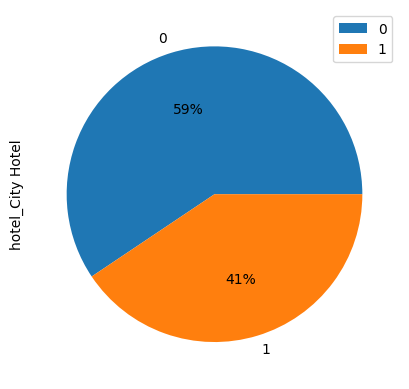

In [75]:
calc.groupby('is_canceled').sum().plot(kind='pie', y='hotel_City Hotel', autopct='%1.0f%%') #shows the pie graph for cancaltions, with 0 being false and 1 being true, eg 1 is a cancled reservation

In [76]:
calc = df[['hotel_Resort Hotel', 'is_canceled']] # creates a new data set to make a graph out of, using only wanted columns for graph
calc = calc[calc['hotel_Resort Hotel'] != False] # done to see only the resorts
calc[['is_canceled']].value_counts() # checks to see if above code worked

,count
is_canceled,
0,26343
1,10362


<Axes: ylabel='hotel_Resort Hotel'>

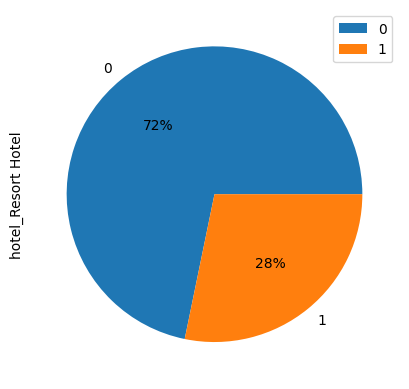

In [77]:
calc.groupby('is_canceled').sum().plot(kind='pie', y='hotel_Resort Hotel', autopct='%1.0f%%')
# shows the pie graph for cancaltions, with 0 being false and 1 being true, eg 1 is a cancled reservation
# pie graph used as percentages are more useful when looking at room cancellations

##Identifying the most frequently ordered meal types.

<Axes: xlabel='meal'>

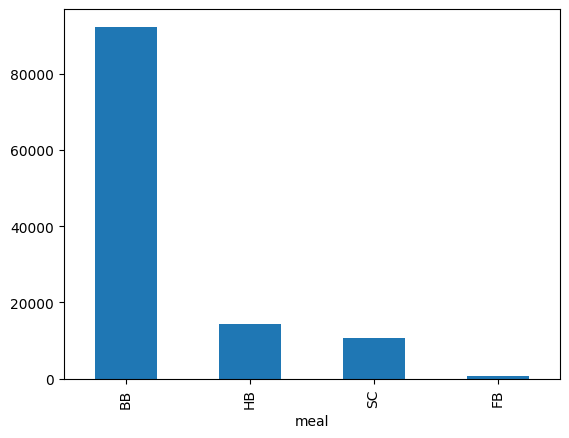

In [78]:
meals_calc = pd.read_csv('hotel_bookings.csv') # creates a new data set to make a graph out of, using only wanted columns for graph
meals_calc = meals_calc[meals_calc['meal'] != "Undefined"]
meals_calc['meal'].value_counts().plot(kind='bar') # shows that BB is the most ordered meal Bar graph used to show amount ordered so hotel can order the needed ingredients and not over order

## Determining the number of returning guests.

<Axes: xlabel='is_repeated_guest'>

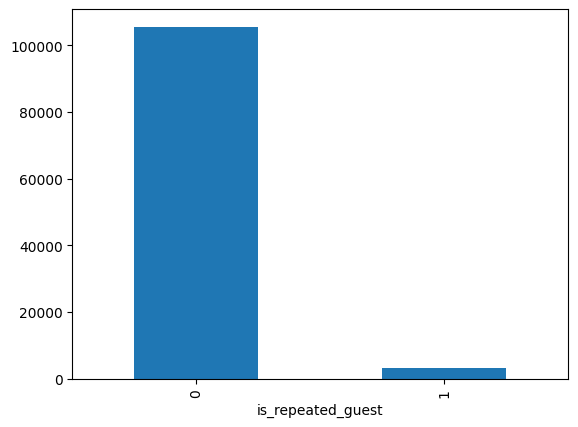

In [79]:
df['is_repeated_guest'].value_counts().plot(kind='bar') # shows the returning number of guests

##Discovering the most booked room types.

<Axes: xlabel='reserved_room_type'>

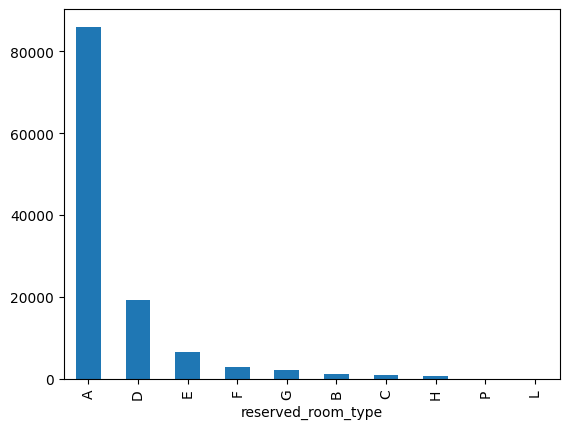

In [80]:
room_calc =  pd.read_csv('hotel_bookings.csv')
room_calc = room_calc[['reserved_room_type']]
room_calc['reserved_room_type'].value_counts().plot(kind='bar')
# shows that the most common booked room type is A Bar graph was used as shows total numbers, as oppsed to pie graphs which is useful when

##Exploring correlations between room types and cancellations.

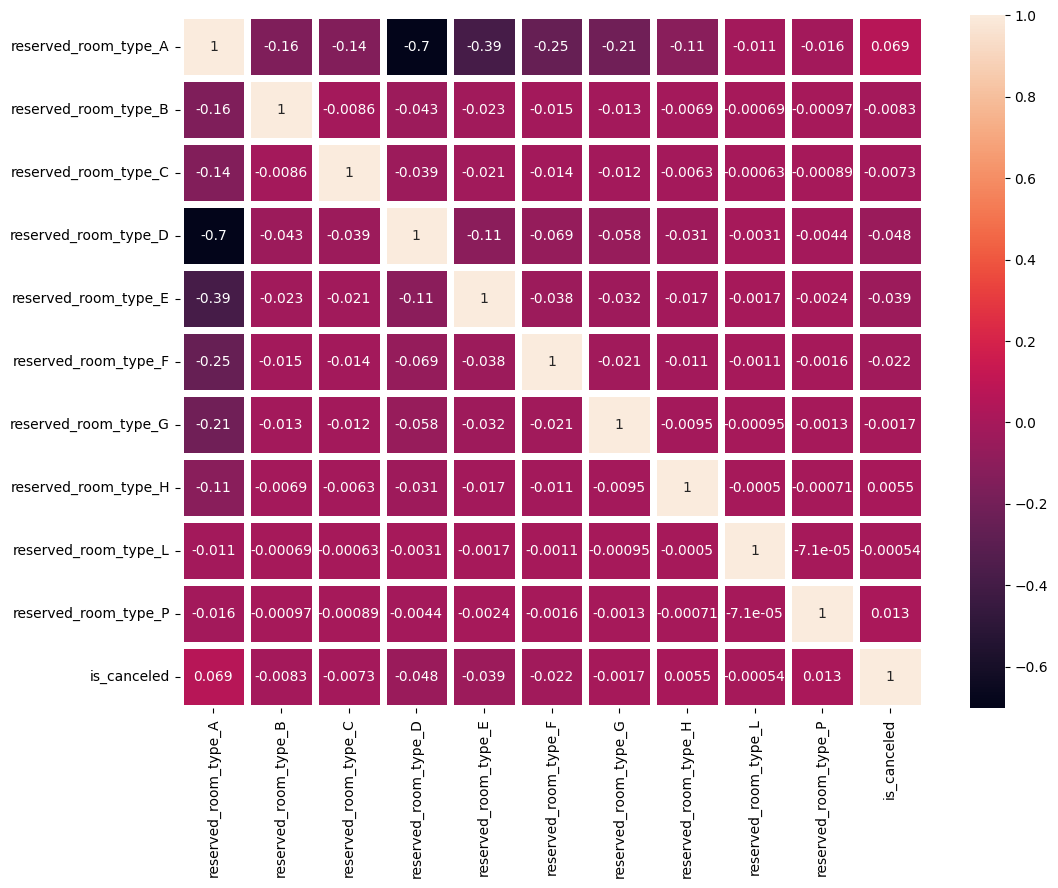

In [81]:
import seaborn as sns #imported for heat map
import matplotlib.pyplot as plt

room_calc = pd.read_csv('hotel_bookings.csv')
room_calc = room_calc[['reserved_room_type', "is_canceled"]]
room_calc = pd.get_dummies(room_calc, columns=['reserved_room_type'])

test = room_calc[['reserved_room_type_A','reserved_room_type_B','reserved_room_type_C','reserved_room_type_D','reserved_room_type_E','reserved_room_type_F','reserved_room_type_G','reserved_room_type_H','reserved_room_type_L','reserved_room_type_P', 'is_canceled']]

# Compute correlation matrix
co_mtx = test.corr(numeric_only=True)

# Plot correlation heatmap

plt.figure(figsize=(12, 9))
sns.heatmap(co_mtx, annot=True, linewidths=5)

# Display heatmap
plt.show() # hear map shows that the room type that has the highest correrlations with being cancelled is type A, this shows that they can account for the most cancellations to be from room type A bookings

Feature Engineering


In [82]:
#encoding was done in a previous section

pearson_corr = df.corr()['is_canceled'] # prints out how linearerly corralted each varrible is to the target varrible, 'is_canceled'
pearson_corr

,is_canceled
is_canceled,1.000000
lead_time,0.284215
arrival_date_week_number,0.015458
adults,0.059005
children,0.011042
babies,-0.030041
is_repeated_guest,-0.076770
previous_cancellations,0.108416
previous_bookings_not_canceled,-0.058876
booking_changes,-0.153055


In [83]:
spearman_corr = df.corr(method='spearman')['is_canceled'] # checks nonlinear corraltions to the target varrible
spearman_corr

,is_canceled
is_canceled,1.000000
lead_time,0.305863
arrival_date_week_number,0.014860
adults,0.062179
children,0.003597
babies,-0.031865
is_repeated_guest,-0.076770
previous_cancellations,0.268365
previous_bookings_not_canceled,-0.115558
booking_changes,-0.169087


Classifier Training

In [84]:
df.isnull().sum()

,0
is_canceled,0
lead_time,0
arrival_date_week_number,0
adults,0
children,0
babies,0
is_repeated_guest,0
previous_cancellations,0
previous_bookings_not_canceled,0
booking_changes,0


In [85]:
from sklearn.model_selection import train_test_split, GridSearchCV  # To split data and perform hyperparameter optimization
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

#Drop target data and set target data
X = df.drop('is_canceled', axis=1)
y = df['is_canceled']

#normalizing the data
smote = SMOTE(random_state=42)
X_resampled, Y_resampled = smote.fit_resample(X, y)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_resampled, Y_resampled, test_size=0.2, random_state=42)  # Split dataset into train and test sets

In [ ]:
from sklearn.ensemble import RandomForestClassifier  # imports Random Forest Classifier
# Parts of the fallowing code were adpted from (A. Anderson, past assignment(Introduction to AI-Code assigment 1), 20 June, 2025)

#start of model section
model_params = {

     'random_forest': {
        'model': RandomForestClassifier(),  # Random Forest Classifier instance
        'params': {
            'n_estimators': [10, 50, 100],  # Number of trees in the forest
            'max_depth': [None, 10, 20],  # Maximum depth of the tree
            'min_samples_split': [2, 5, 10]  # Minimum number of samples required to split an internal node
        }
    },

}
# List that stores results of GridSearchCV
results = []  # Initialize an empty list to store model results

for model_name, mp in model_params.items():  # Loop through the model dictionary

    # Initialize GridSearchCV with model, parameters, and cross-validation settings
    grid_search = GridSearchCV(mp['model'], mp['params'], cv=5, scoring='accuracy')  # Perform 5-fold cross-validation

    # Fit the GridSearchCV instance on the training data
    grid_search.fit(X_train, y_train)  # Train the model on the training data

    # Append model results to the results list
    results.append({
        'model': model_name ,  # Name of the model
        'best_params': grid_search.best_params_,  # Best hyperparameters found
        'best_score': grid_search.best_score_  # Best cross-validation score
    })
    # Convert results to a DataFrame for easy viewing
results_df = pd.DataFrame(results)  # Create a DataFrame from the results list
print(results_df)  # Display results of all models

           model                                        best_params  \
0  random_forest  {'max_depth': None, 'min_samples_split': 2, 'n...   

   best_score  
0    0.873068  


shows the accuracy of the trained AI model at being 87%

In [87]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

best_model = RandomForestClassifier(**results[0]['best_params'])

# Train the best model on the training data
best_model.fit(X_train, y_train)  # Fit the model to the training data

# Predict target variable for test data
y_pred = best_model.predict(X_test)  # Predict the target for test set

# Evaluates the model
accuracy = accuracy_score(y_test, y_pred)

# Prints out the classification report
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.86      0.90      0.88     13876
           1       0.90      0.85      0.87     13820

    accuracy                           0.88     27696
   macro avg       0.88      0.88      0.88     27696
weighted avg       0.88      0.88      0.88     27696



All the checked values are well above the minimum values as f1-score was also used to check to the model and it was above the minmum percentage (70%). This shows that the AI model is working as intended.

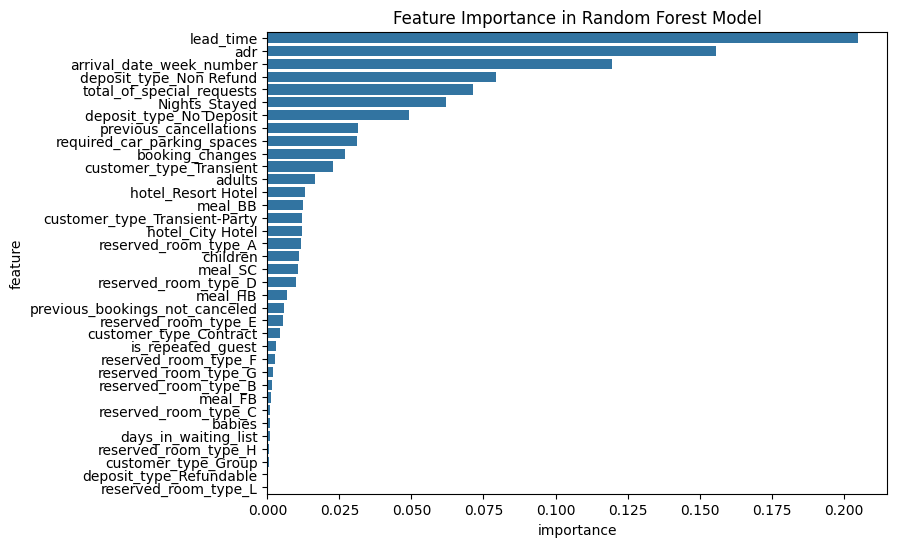

In [90]:
# Get feature importance scores
importances = model.feature_importances_

# Create a DataFrame for better visualization
feature_importance_df = pd.DataFrame({
    'feature': X.columns,
    'importance': importances
})

# Sort by importance
feature_importance_df = feature_importance_df.sort_values(by='importance', ascending=False)

# Plot feature importance
plt.figure(figsize=(8, 6))
sns.barplot(x='importance', y='feature', data=feature_importance_df)
plt.title('Feature Importance in Random Forest Model')
plt.show()

The above graph shows that lead time is by far the most impoartant factor in predicting if a resevertion is going to be cancled. This makes sense as the further back someone makes a booking, the more likely it is to be a plan that they are going to fallow through with their plan.

The fourth important feature is the refund being non refundable, this makes sense as the people who made the booking will not receive anything for cancleing, meaning that it would be wasted money if they dont go to the booked hotel.

My model is highly reliable as its accuracy rates are 88%, proving that it is realible.